# Revisión de columnas — ACI 318-25
P-M-M + corte + confinamiento (SMF, §18.7). Cláusulas: §10, §22.4 (interacción), §18.7.5 (confinamiento, Ash), §18.7.6 (Ve, Mpr), §21.2.2 (phi), §25.7.3 (espiral).

**Unidades:** resultados en tonf / m; materiales en MPa.

In [1]:
import sys, pathlib
# Make the notebook self-contained: add the repo root (the folder that
# contains design/common) to sys.path regardless of the run cwd.
ROOT = pathlib.Path.cwd()
for _ in range(5):
    if (ROOT / 'design' / 'common').is_dir():
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from design import Concrete, Steel, Bar, Beam, Column, Wall
from design import RectangularSection, WallSection
from design.beams.beam import BeamDemands
from design.columns.column import ColumnDemands
from design.walls.wall import WallDemands
from design.sections.reinforcement import RebarLayout, perimeter_bars, two_layer_bars
from design.common.units import units_from
from design.common.probable import mpr_at_axial, probable_interaction_diagram
from design.analysis.section_analysis import pm_curve

# Presentation: results in tonf / m ; materials in MPa (N/mm^2)
U = units_from('Tonf_m_C')      # forces -> tonf, moments -> tonf*m, lengths -> m
MAT = units_from('N_mm_C')      # stresses -> MPa
print('Results in:', U.name, '| materials in:', MAT.name)
print('1 tonf =', round(1/U.force_factor, 5), 'kN')


Results in: Tonf_m_C | materials in: N_mm_C
1 tonf = 9.80665 kN


In [2]:
def plot_pm(diagram, *, title, demand=None, mark_p0=True, nominal=None):
    """Plot a phi-reduced P-M interaction diagram (tonf, tonf*m), marking
    the Mpr at zero axial and an optional demand point."""
    Mn = np.array(diagram.phi_Mn) * U.moment_factor
    Pn = np.array(diagram.phi_Pn) * U.force_factor
    fig, ax = plt.subplots(figsize=(5.2, 5.6))
    ax.plot(Mn, Pn, '-', lw=2, color='#1f77b4', label='phi P-M (design)')
    if nominal is not None:
        Mnn = np.array([p.Mn for p in nominal.points]) * U.moment_factor
        Pnn = np.array([p.Pn for p in nominal.points]) * U.force_factor
        order = np.argsort(Pnn)
        ax.plot(Mnn[order], Pnn[order], '--', lw=1.2, color='#888',
                label='nominal P-M')
    if mark_p0:
        # moment at P = 0 (Mpr-style) read off the nominal curve
        if nominal is not None:
            order = np.argsort([p.Pn for p in nominal.points])
            Pn_s = np.array([nominal.points[i].Pn for i in order])
            Mn_s = np.array([nominal.points[i].Mn for i in order])
            m0 = float(np.interp(0.0, Pn_s, Mn_s)) * U.moment_factor
            ax.plot(m0, 0.0, 'o', color='crimson', ms=8,
                    label=f'M at P=0 = {m0:.1f} tonf*m')
    if demand is not None:
        md_, pd_ = demand
        ax.plot(md_, pd_, 's', color='green', ms=9, label='demand')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xlabel('phi*Mn  [tonf*m]'); ax.set_ylabel('phi*Pn  [tonf]')
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


## Ejercicio 1 — Evaluar un armado mínimo
Columna 600×600 con $\rho_g\approx1\%$ (mínimo §10.6.1: $0.01\le\rho_g\le0.06$ sísmico).

In [3]:
c = Concrete(fc=28); s = Steel(fy=420, grade=60)
grp = perimeter_bars(b=600, h=600, cover=50, n_x=3, n_y=3, bar=Bar(25), steel=s)
sec = RectangularSection(b=600, h=600, concrete=c, rebar=RebarLayout(groups=(grp,)))
col = Column(section=sec, lu=3000, Av=2*71.0, fyt=420, s=100, seismic=True, hx=180.0)
Ag = 600*600; rho_g = grp.total_area/Ag
print(f'rho_g = {rho_g:.4f}  (min 0.01, max 0.06 seismic)  bars: 8 phi25')

rho_g = 0.0109  (min 0.01, max 0.06 seismic)  bars: 8 phi25


### 1.2 Diagrama de interacción racional y Mpr
El tope $\phi P_{n,max}=\phi\,0.80\,P_o$ (§22.4.2.1) debe ser una meseta plana; el $M_{pr}$ a $P=0$ y al $P_u$ actuante.

In [4]:
cap = col.capacity()
print('Po          =', U.fmt_force(cap.Po))
print('phi_Pn_max  =', U.fmt_force(cap.phi_Pn_max),
      '= 0.65*0.80*Po =', U.fmt_force(0.65*0.80*cap.Po))
print('To          =', U.fmt_force(cap.To))
print('max phi_Mn  =', U.fmt_moment(max(cap.diagram_x.phi_Mn)))
print('Mpr @P=0    =', U.fmt_moment(mpr_at_axial(sec, Nu=0.0)))
print('Mpr @Pu=2000=', U.fmt_moment(mpr_at_axial(sec, Nu=2000.0)))

Po          = 1032.3 Tonf
phi_Pn_max  = 536.8 Tonf = 0.65*0.80*Po = 536.8 Tonf
To          = -168.2 Tonf
max phi_Mn  = 76.2 Tonf.m
Mpr @P=0    = 54.2 Tonf.m
Mpr @Pu=2000= 89.6 Tonf.m


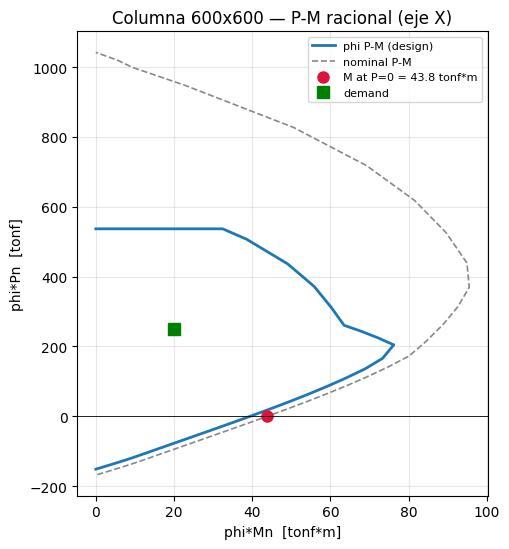

In [5]:
nom = pm_curve(sec, n_points=60, angle_deg=0.0)
plot_pm(cap.diagram_x, title='Columna 600x600 — P-M racional (eje X)',
        demand=(20.0, 250.0), nominal=nom)

### 1.3 Verificación frente a demandas
Demanda biaxial $(P_u, M_{ux}, M_{uy}, V_u)$ en tonf·m.

In [6]:
chk = col.check(ColumnDemands(Pu=2000.0, Mux=250.0, Muy=120.0, Vux=150.0))
print('ratio PMM  =', round(chk.ratio_pmm,3), ' [', 'PASS' if chk.ratio_pmm<=1 else 'FAIL', ']')
print('ratio shear=', round(chk.ratio_shear,3))
print('Ash ok     =', chk.ash_ok, '| hx ok =', chk.hx_ok)
print('passed     =', chk.passed)

ratio PMM  = 0.478  [ PASS ]
ratio shear= 1.439
Ash ok     = False | hx ok = False
passed     = False


## Ejercicio 2 — Diseño desde la sección y las demandas
`design()` propone el confinamiento (Ash §18.7.5, hoops, lo) y el Ve.

In [7]:
res = col.design(ColumnDemands(Pu=2000, Mux=250, Muy=120, Vux=150))
p = res.envelope
print('Ash_x req =', round(p.ash_required_x,0), 'mm^2  prov', round(p.av_provided_x,0),
      f'({p.n_legs_x} legs phi{p.db_hoop:.0f})')
print('Ash_y req =', round(p.ash_required_y,0), 'mm^2  prov', round(p.av_provided_y,0),
      f'({p.n_legs_y} legs phi{p.db_hoop:.0f})')
print('s confined=', U.fmt_length(p.spacing_confined), '| lo =', U.fmt_length(p.lo))
if res.capacity.Ve_capacity:
    print('Ve capacity=', U.fmt_force(res.capacity.Ve_capacity))

Ash_x req = 431.0 mm^2  prov 603.0 (3 legs phi16)
Ash_y req = 431.0 mm^2  prov 603.0 (3 legs phi16)
s confined= 0.100 m | lo = 0.600 m
Ve capacity= 67.5 Tonf


## Resumen
- Diagrama P-M **racional**: tope $\phi P_{n,max}=0.65\cdot0.80\,P_o$ como meseta plana (§22.4.2.1), transición $\phi$ por $\varepsilon_t$ (§21.2.2).
- $A_{sh}$ por Tabla 18.7.5.4 incluyendo la expresión (c) con axial alta.
- $M_{pr}$ disponible a $P=0$ y al $P_u$ actuante (§18.7.6.1.1).